## Churn Project 
## Preprocess/Cleaning Data
***
**Authors:** Ava Cannatelli, Natalie Pond, Sarah Sizemore

**Date:** October 16, 2026

# Audience and Purpose
**Audience**: We created this notebook for someone who will use our cleaned data to build a customer churn model, whether that's another student or an analyst on our team. We're assuming they understand basic Python and modeling, but may not know what issues were in the original dataset.

**Purpose**: A telecom company wants to understand why customers leave and which customers are most likely to churn. Eventually, the goal is to predict whether a customer will leave using the Churn variable (Yes or No). Before we can build a model, though, we need to make sure the data is reliable. In this notebook, we examine the original dataset, clean up any issues we find, and explain the decisions we make along the way. The actual modeling will come later.

## Business Value Proposition

![Business Value Proposition](BVP%20%281%29.png)


### Data Description

We are using the class-provided IBM Telco Customer Churn dataset (`Churn_class_project.csv`) and its data dictionary.

The dataset contains 7,043 customers and 17 variables. Each row represents one customer, and the columns give us information about their demographics, account details, services, and customer experience.

The variables can be broken into a few categories:

- **Customer identifier:** `customerID`
- **Demographics:** `gender`, `SeniorCitizen`, `CustomerAge`, and `AnnualIncome`
- **Account and billing:** `tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod`, and `AveragePaymentDelayDays`
- **Services:** `PhoneService`, `MultipleLines`, `InternetService`, and `TechSupport`
- **Usage and experience:** `MonthlyCallMinutes` and `CustomerSatisfactionScore`
- **Target variable:** `Churn` (Yes/No)

We noticed that the data dictionary lists `SeniorCitizen` as 0/1, but our dataset uses Yes/No. Since the values are already categorical, we don't need to recode them at this stage.

We also noticed some categories, such as "No phone service" and "No internet service," that should agree with other columns. We'll check those relationships during cleaning to make sure the information is consistent.


In [4]:
import pandas as pd

In [5]:
## Creating a copy of our dataset 
raw = pd.read_csv("Churn_class_project.csv")
df = raw.copy()

# Inspection


### Initial Data Inspection

Before making any changes, we wanted to get a better understanding of the dataset.

We started by checking:

- The number of rows and columns
- Column names and data types
- Missing values
- Duplicate records
- Summary statistics
- Unique values
- Correlations between numeric variables

This helped us identify which areas needed cleaning before we could move forward.


In [6]:
df.head()

,customerID,gender,SeniorCitizen,tenure,PhoneService,MultipleLines,InternetService,TechSupport,Contract,PaperlessBilling,PaymentMethod,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore,Churn
0,7590-VHVEG,Female,No,1.0,No,Yes,DSL,No,Month-to-month,No,Electronic check,77.0,39408.0,0.0,11.4,6.0,No
1,5575-GNVDE,Male,No,34.0,Yes,No,DSL,No,One year,Yes,Mailed check,22.0,102292.0,375.1,0.5,6.6,No
2,3668-QPYBK,Male,No,2.0,Yes,No phone service,DSL,No,Month-to-month,Yes,Mailed check,43.0,26869.0,373.6,3.4,6.2,Yes
3,7795-CFOCW,Male,No,45.0,No,Yes,DSL,Yes,One year,Yes,NaN,71.0,90565.0,0.0,1.4,6.8,No
4,9237-HQITU,Female,No,2.0,Yes,No,Fiber optic,No,Month-to-month,Yes,Electronic check,NaN,83510.0,221.7,5.8,6.3,Yes


In [7]:
df.tail()

,customerID,gender,SeniorCitizen,tenure,PhoneService,MultipleLines,InternetService,TechSupport,Contract,PaperlessBilling,PaymentMethod,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore,Churn
7038,6840-RESVB,Male,No,24.0,Yes,No,DSL,Yes,One year,No,Mailed check,72.0,33447.0,332.9,0.1,9.1,No
7039,2234-XADUH,Female,No,72.0,Yes,No,Fiber optic,No,One year,Yes,Credit card (automatic),46.0,58274.0,688.3,1.6,7.0,No
7040,4801-JZAZL,Female,No,11.0,No,Yes,DSL,No,Month-to-month,Yes,Electronic check,46.0,47462.0,0.0,4.6,6.4,No
7041,8361-LTMKD,Male,Yes,4.0,Yes,Yes,Fiber optic,No,Month-to-month,Yes,Mailed check,40.0,71378.0,550.2,6.7,5.7,Yes
7042,3186-AJIEK,Male,No,66.0,Yes,Yes,Fiber optic,Yes,Two year,Yes,Bank transfer (automatic),58.0,34922.0,455.3,2.0,6.5,No


In [8]:
df.shape

(7043, 17)

In [9]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'tenure', 'PhoneService',
       'MultipleLines', 'InternetService', 'TechSupport', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'CustomerAge', 'AnnualIncome',
       'MonthlyCallMinutes', 'AveragePaymentDelayDays',
       'CustomerSatisfactionScore', 'Churn'],
      dtype='object')

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customerID                 7043 non-null   object 
 1   gender                     7043 non-null   object 
 2   SeniorCitizen              7043 non-null   object 
 3   tenure                     6761 non-null   float64
 4   PhoneService               7043 non-null   object 
 5   MultipleLines              7043 non-null   object 
 6   InternetService            7043 non-null   object 
 7   TechSupport                7043 non-null   object 
 8   Contract                   7043 non-null   object 
 9   PaperlessBilling           7043 non-null   object 
 10  PaymentMethod              6761 non-null   object 
 11  CustomerAge                6973 non-null   float64
 12  AnnualIncome               6973 non-null   float64
 13  MonthlyCallMinutes         6973 non-null   float

In [11]:
df.dtypes

customerID                    object
gender                        object
SeniorCitizen                 object
tenure                       float64
PhoneService                  object
MultipleLines                 object
InternetService               object
TechSupport                   object
Contract                      object
PaperlessBilling              object
PaymentMethod                 object
CustomerAge                  float64
AnnualIncome                 float64
MonthlyCallMinutes           float64
AveragePaymentDelayDays      float64
CustomerSatisfactionScore    float64
Churn                         object
dtype: object

In [12]:
df.isna().sum()

customerID                     0
gender                         0
SeniorCitizen                  0
tenure                       282
PhoneService                   0
MultipleLines                  0
InternetService                0
TechSupport                    0
Contract                       0
PaperlessBilling               0
PaymentMethod                282
CustomerAge                   70
AnnualIncome                  70
MonthlyCallMinutes            70
AveragePaymentDelayDays       70
CustomerSatisfactionScore     70
Churn                          0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.describe()

,tenure,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore
count,6761.000000,6973.000000,6973.000000,6973.000000,6973.000000,6973.000000
mean,32.441651,46.689230,62124.351642,467.187079,3.325742,6.859587
std,24.561694,16.576262,29417.754988,226.335372,3.003101,1.387753
min,0.000000,18.000000,18000.000000,0.000000,0.000000,1.500000
25%,9.000000,35.000000,41357.000000,346.100000,1.200000,5.900000
50%,29.000000,44.000000,55841.000000,494.500000,2.500000,6.900000
75%,56.000000,57.000000,76273.000000,623.100000,4.500000,7.800000
max,72.000000,90.000000,250000.000000,1161.500000,24.000000,10.000000


In [15]:
df.nunique()

customerID                   7043
gender                          2
SeniorCitizen                   2
tenure                         73
PhoneService                    2
MultipleLines                   3
InternetService                 3
TechSupport                     3
Contract                        3
PaperlessBilling                2
PaymentMethod                   4
CustomerAge                    73
AnnualIncome                 6682
MonthlyCallMinutes           4044
AveragePaymentDelayDays       187
CustomerSatisfactionScore      80
Churn                           2
dtype: int64

In [16]:
df.corr(numeric_only=True)

,tenure,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore
tenure,1.000000,-0.000696,-0.012589,0.152607,-0.291723,0.273641
CustomerAge,-0.000696,1.000000,-0.002214,0.008655,-0.006822,0.005975
AnnualIncome,-0.012589,-0.002214,1.000000,-0.013683,0.010613,-0.023171
MonthlyCallMinutes,0.152607,0.008655,-0.013683,1.000000,-0.024134,-0.051933
AveragePaymentDelayDays,-0.291723,-0.006822,0.010613,-0.024134,1.000000,-0.222961
CustomerSatisfactionScore,0.273641,0.005975,-0.023171,-0.051933,-0.222961,1.000000



### What We Found During Our Initial Inspection

After looking through the dataset, we noticed a few things:

- **Dataset size:** We have 7,043 rows and 17 columns. Six columns are numeric, while the other 11 are stored as text.
- **Duplicates:** We didn't find any duplicate rows or customer IDs.
- **Missing values:** Seven columns contain missing values. `tenure` and `PaymentMethod` each have 282 missing values, while five other numeric columns each have 70.
- **Incomplete rows:** In total, 877 customers (12.5%) are missing at least one value. If we removed every incomplete row, we would lose about one out of every eight customers.
- **Value ranges:** The numeric values generally seem reasonable. We didn't find any negative values, ages range from 18 to 90, satisfaction scores range from 1.5 to 10, and tenure ranges from 0 to 72 months.
- **Correlations:** Most numeric variables have very weak relationships with one another. Tenure is one exception, with some relationship to payment delays, satisfaction, and call minutes.

Overall, the dataset seems like a good starting point, but there are several issues we need to address before using it for modeling.


In [17]:
# Shared plot style used by all charts below
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ACCENT, NEUTRAL, INK = "#2F5D8C", "#B8BEC7", "#333A44"

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": NEUTRAL,
    "axes.labelcolor": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
    "figure.dpi": 110
})

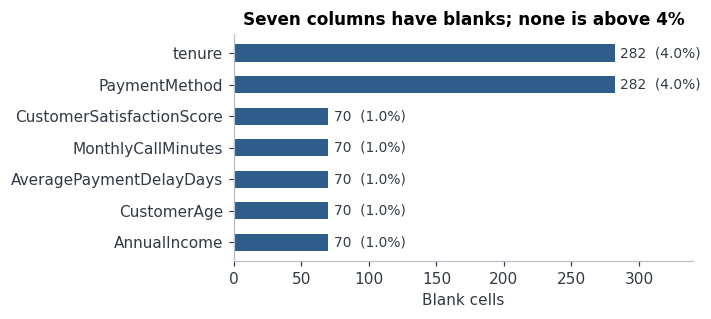

Rows with at least one blank: 877 of 7043 (12.5%)


In [18]:
# How much is missing by column, using the original data
miss = raw.isna().sum()
miss = miss[miss > 0].sort_values()

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh(miss.index, miss.values, color=ACCENT, height=0.55)

for y, v in enumerate(miss.values):
    ax.text(
        v + 4, y,
        f"{v}  ({v/len(raw):.1%})",
        va="center",
        fontsize=9,
        color=INK
    )

ax.set_xlim(0, 340)
ax.set_xlabel("Blank cells")
ax.set_title("Seven columns have blanks; none is above 4%")

plt.tight_layout()
plt.show()

print(
    f"Rows with at least one blank: "
    f"{raw.isna().any(axis=1).sum()} of {len(raw)} "
    f"({raw.isna().any(axis=1).mean():.1%})"
)


### Missing Values

The chart above shows which columns contain missing values and how many values are missing from each.

While no individual column is missing more than 4% of its values, 12.5% of customers have at least one missing value.

We don't want to lose that many customers by simply deleting incomplete rows, especially when we may be able to estimate the missing information.

Because of this, we decided to look into different ways of filling in missing values while keeping as much of the original data as possible.


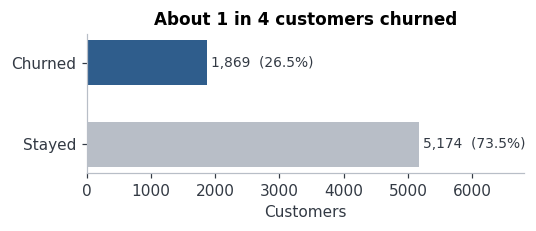

In [39]:
# Check how balanced our response variable is
counts = raw["Churn"].value_counts()

fig, ax = plt.subplots(figsize=(5, 2.2))

ax.barh(
    ["Stayed", "Churned"],
    [counts["No"], counts["Yes"]],
    color=[NEUTRAL, ACCENT],
    height=0.55
)

for y, v in enumerate([counts["No"], counts["Yes"]]):
    ax.text(
        v + 60, y,
        f"{v:,}  ({v/len(raw):.1%})",
        va="center",
        fontsize=9,
        color=INK
    )

ax.set_xlim(0, 6800)
ax.set_xlabel("Customers")
ax.set_title("About 1 in 4 customers churned")

plt.tight_layout()
plt.show()


### Looking at Churn

Of the 7,043 customers, 1,869 (26.5%) churned. This means roughly one out of every four customers left the company.

We noticed that the dataset is somewhat imbalanced because there are almost three customers who stayed for every customer who left.

This is something we'll need to keep in mind when we start modeling. For example, a model that predicts every customer will stay would already be about 73% accurate, even though it wouldn't actually identify anyone at risk of leaving.

We aren't making changes to the churn distribution during cleaning, but we'll want to account for it when evaluating our model later.



## Data Cleaning and Preparation

Now that we have a better understanding of the dataset, we can start cleaning it.

We first want to check whether related columns agree with each other. This is important because even if a column doesn't have missing values, it could still contain incorrect or inconsistent information.


In [19]:
# contingency table for multiple lines and phone service
contingency_table1 = pd.crosstab(df['MultipleLines'], df['PhoneService'])
contingency_table1

PhoneService,No,Yes
MultipleLines,,
No,318,3072
No phone service,70,612
Yes,294,2677


In [20]:
# contingency table for tech support and internet service
contingency_table2 = pd.crosstab(df['TechSupport'], df['InternetService'])
contingency_table2

InternetService,DSL,Fiber optic,No
TechSupport,,,
No,1243,2230,0
No internet service,0,0,1526
Yes,1178,866,0


In [21]:
# contingency table for phone service and tech support
contingency_table3 = pd.crosstab(df['PhoneService'], df['TechSupport'])
contingency_table3

TechSupport,No,No internet service,Yes
PhoneService,,,
No,393,0,289
Yes,3080,1526,1755


In [22]:
# correlation between phone service and churn
corrrelation1 = df['PhoneService'].astype('category').cat.codes.corr(df['Churn'].astype('category').cat.codes)
corrrelation1

np.float64(0.011941980029002906)


### Checking Whether Related Columns Agree

We compared a few columns that should have consistent information about the services customers use.

**1. TechSupport and InternetService**

We expected customers without internet service to have "No internet service" listed under `TechSupport`.

All 1,526 customers in this category were consistent, so we didn't find anything that needed to be corrected.

**2. PhoneService and TechSupport**

These columns don't necessarily need to match because customers can have internet service without having phone service.

We didn't find any issues with this relationship that needed to be fixed.

**3. MultipleLines and PhoneService**

This is where we noticed a much bigger problem.

We expected customers without phone service to have "No phone service" listed under `MultipleLines`. However, we found:

- 612 customers were marked as having phone service but had "No phone service" under `MultipleLines`.
- Another 612 customers were marked as not having phone service but had a conflicting value under `MultipleLines`.
- Altogether, 1,224 customers (17.4%) had inconsistent information between these columns.

**Which Column Should We Trust?**

To figure this out, we looked at `MonthlyCallMinutes`.

Of the 682 customers marked as not having phone service, 678 had exactly zero call minutes. The remaining four had missing values.

We also noticed that none of the customers marked as having phone service had zero call minutes.

This makes us more confident in `PhoneService` than `MultipleLines`. It looks like some of the `MultipleLines` values may have gotten mixed up.

**Does This Matter for Predicting Churn?**

We also compared churn rates across the categories in both columns. The rates were very similar, which suggests that neither column has a particularly strong relationship with churn.

Because of the inconsistencies in `MultipleLines` and the limited relationship with churn, we decided that removing both columns would be the safest option.

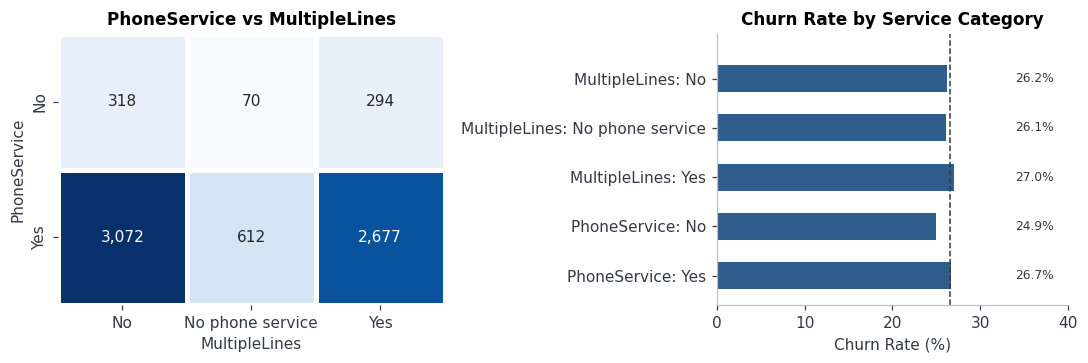

In [40]:

# Compare inconsistent service values and churn rates
# using the original data

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 3.4),
    gridspec_kw={"width_ratios": [1.1, 1]}
)

ct = pd.crosstab(
    raw["PhoneService"],
    raw["MultipleLines"]
)

sns.heatmap(
    ct,
    annot=True,
    fmt=",d",
    cmap="Blues",
    cbar=False,
    linewidths=2,
    linecolor="white",
    ax=axes[0]
)

axes[0].set_title("PhoneService vs MultipleLines")
axes[0].set_xlabel("MultipleLines")
axes[0].set_ylabel("PhoneService")

rate = (
    raw.assign(y=(raw["Churn"] == "Yes").astype(int))
       .melt(
           id_vars="y",
           value_vars=["PhoneService", "MultipleLines"],
           var_name="column",
           value_name="level"
       )
       .groupby(["column", "level"])["y"]
       .mean()
       .mul(100)
)

labels = [f"{c}: {l}" for c, l in rate.index]

axes[1].barh(
    labels[::-1],
    rate.values[::-1],
    color=ACCENT,
    height=0.55
)

axes[1].axvline(
    26.5,
    color=INK,
    lw=1,
    ls="--"
)

for y, v in enumerate(rate.values[::-1]):
    axes[1].text(
        34, y,
        f"{v:.1f}%",
        va="center",
        fontsize=8,
        color=INK
    )

axes[1].set_xlim(0, 40)
axes[1].set_ylim(-0.6, len(rate) - 0.1)
axes[1].set_xlabel("Churn Rate (%)")
axes[1].set_title("Churn Rate by Service Category")

plt.tight_layout()
plt.show()



### What the Service Comparison Shows

The charts help us see two things:

- **Inconsistent service information:** There are a lot of customers whose `PhoneService` and `MultipleLines` values don't agree.
- **Similar churn rates:** Churn stays around 25–27% across most categories.

This supports our decision to remove both columns. We don't want the model learning from information that we know is inconsistent, especially when the columns don't appear to add much predictive value.


In [23]:
## Preprocessing the data & Regression Imputation Code
import pandas as pd
import numpy as np
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
# List of numeric columns needing regression imputation
num_cols = [
    'tenure', 'CustomerAge', 'AnnualIncome', 
    'MonthlyCallMinutes', 'AveragePaymentDelayDays', 'CustomerSatisfactionScore'
]

# 2. Fit Iterative Imputer (Multivariate Regression Imputation)
imputer = IterativeImputer(random_state=42, max_iter=10)
df[num_cols] = imputer.fit_transform(df[num_cols])

# Ensure tenure is non-negative
df['tenure'] = df['tenure'].clip(lower=0)

# 3. Impute categorical PaymentMethod with Mode
mode_pm = df['PaymentMethod'].mode()[0]
df['PaymentMethod'] = df['PaymentMethod'].fillna(mode_pm)

# 4. Enforce domain rules per Data Dictionary
df.loc[df['PhoneService'] == 'No', 'MonthlyCallMinutes'] = 0.0
df.loc[df['PhoneService'] == 'No', 'MultipleLines'] = 'No phone service'
df.loc[df['InternetService'] == 'No', 'TechSupport'] = 'No internet service'

# Create binary response target
df['Churn_Binary'] = (df['Churn'] == 'Yes').astype(int)

# Verify zero missing values remain
print("Missing values per column after regression imputation:")
print(df.isnull().sum())

Missing values per column after regression imputation:
customerID                   0
gender                       0
SeniorCitizen                0
tenure                       0
PhoneService                 0
MultipleLines                0
InternetService              0
TechSupport                  0
Contract                     0
PaperlessBilling             0
PaymentMethod                0
CustomerAge                  0
AnnualIncome                 0
MonthlyCallMinutes           0
AveragePaymentDelayDays      0
CustomerSatisfactionScore    0
Churn                        0
Churn_Binary                 0
dtype: int64



### Handling Missing Values

We found that 877 customers (12.5%) had at least one missing value. Since we would lose quite a few customers by deleting every incomplete row, we decided to fill in the missing values instead.

We used different methods depending on the type of information.

**1. Numeric Variables**

For `tenure`, `CustomerAge`, `AnnualIncome`, `MonthlyCallMinutes`, `AveragePaymentDelayDays`, and `CustomerSatisfactionScore`, we used `IterativeImputer`. We used model-based imputation to estimate missing numeric values. This method uses relationships between variables to predict missing values based on the information available in other variables. Rather than filling missing values with a simple average or median, it iteratively estimates missing values and updates those estimates as the process continues. This approach helps preserve relationships between variables in the dataset.

Instead of replacing every missing value with the average, this method uses patterns in the other numeric columns to estimate what the missing value might be.

We used 10 iterations and set `random_state=42` so the process would be reproducible.

We also made sure that tenure could not be negative.

**2. PaymentMethod**

Since `PaymentMethod` is categorical, we filled its missing values with the mode, which is the most common category.

In this dataset, that was "Electronic check."

**3. Service-Related Values**

We also used rules from the data dictionary to keep the service information consistent.

- Customers without phone service should have zero monthly call minutes.
- Customers without phone service should have "No phone service" listed under `MultipleLines`.
- Customers without internet service should have "No internet service" listed under `TechSupport`.

We applied these rules after imputation because these values should be determined by the customer's services rather than estimated.

**4. Churn**

We created a new column called `Churn_Binary`:

- 1 = Customer churned
- 0 = Customer stayed

We kept the original `Churn` column too, but the numeric version will be useful when we start modeling.

### Why We Chose This Approach

We wanted to keep all 7,043 customers rather than lose a large portion of our data.

Using information from other columns to estimate missing numeric values seemed more useful than filling everything with the same number.

However, we know that these values are still estimates, so we need to keep that in mind when interpreting our results.



### Limitations of Our Imputation Method

Although our approach allowed us to keep all the customers, there are a few limitations worth mentioning.

**Weak Relationships Between Numeric Variables**

Most of the numeric columns don't have particularly strong relationships with one another. Because of this, the imputed values for `CustomerAge` and `AnnualIncome` tend to be close to their averages.

Tenure has stronger relationships with some of the other variables, so the imputer had more information to work with there.

**Variables Related to Churn**

Some of the columns with missing values, especially `tenure`, `AveragePaymentDelayDays`, and `CustomerSatisfactionScore`, are also related to churn.

Since we estimated some of their values, this could influence our modeling results.

**PaymentMethod**

We filled all 282 missing `PaymentMethod` values with "Electronic check," increasing that category from 2,260 to 2,542 customers.

Electronic check already has the highest churn rate among the payment methods, so adding more customers to this category could affect that relationship.

Its churn rate decreased from about 45% to about 43% after imputation.

**Data Leakage**

We also fitted the imputer before splitting the dataset into training and testing sets.

While we didn't use `Churn` to estimate missing values, the better approach when building our actual model will be to fit the imputer using only the training data.

Overall, we think our approach works for preparing and exploring the dataset, but these are things we'll need to remember when we start modeling.


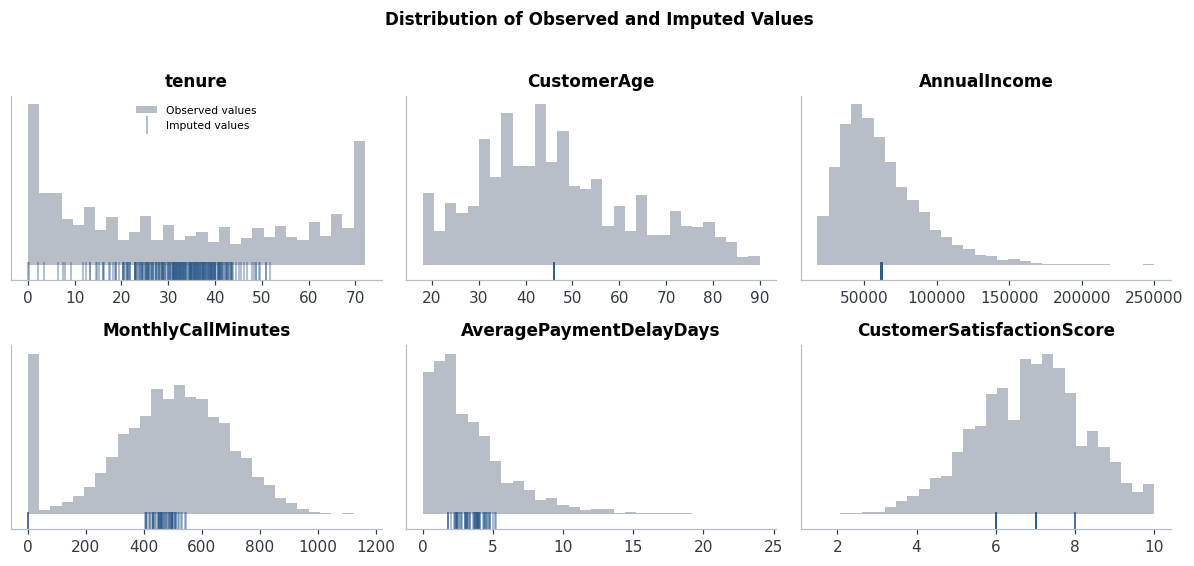

,n_filled,sd_observed,sd_imputed
column,,,
tenure,282,24.56,9.22
CustomerAge,70,16.58,0.00
AnnualIncome,70,29417.75,93.89
MonthlyCallMinutes,70,226.34,115.22
AveragePaymentDelayDays,70,3.00,0.89
CustomerSatisfactionScore,70,1.39,0.48


In [41]:

# Compare original values with imputed values

num_cols = [
    "tenure",
    "CustomerAge",
    "AnnualIncome",
    "MonthlyCallMinutes",
    "AveragePaymentDelayDays",
    "CustomerSatisfactionScore"
]

fig, axes = plt.subplots(2, 3, figsize=(11, 5))
rows = []

for ax, c in zip(axes.ravel(), num_cols):
    was_blank = raw[c].isna()

    ax.hist(
        raw.loc[~was_blank, c],
        bins=30,
        color=NEUTRAL,
        label="Observed values"
    )

    top = ax.get_ylim()[1]
    imp = df.loc[was_blank, c]

    ax.plot(
        imp,
        np.full(len(imp), -0.04 * top),
        "|",
        color=ACCENT,
        markersize=12,
        alpha=0.5,
        clip_on=False,
        label="Imputed values"
    )

    ax.set_title(c)
    ax.set_yticks([])

    rows.append({
        "column": c,
        "n_filled": int(was_blank.sum()),
        "sd_observed": raw[c].std(),
        "sd_imputed": df.loc[was_blank, c].std()
    })

axes[0, 0].legend(
    frameon=False,
    fontsize=7,
    loc="upper center"
)

plt.suptitle(
    "Distribution of Observed and Imputed Values",
    y=1.02,
    fontsize=11,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("column").round(2)



### Checking Our Imputed Values

After filling in the missing values, we compared the estimated values with the original data.

The charts show that many of the estimated values are concentrated near the middle of each variable's distribution.

This is especially noticeable for age and income, where the other numeric columns don't provide much information for estimating missing values.

While this isn't necessarily a problem, it does mean the imputed values may not capture as much variation as the original data.

We'll want to keep this in mind when interpreting our model later.


In [24]:
# Remove the two service columns
df = df.drop(columns=["MultipleLines", "PhoneService"])


### Removing the Phone-Service Columns

After comparing the service-related variables, we decided to remove `MultipleLines` and `PhoneService`.

Our biggest concern was that the two columns had conflicting information for 1,224 customers, or 17.4% of the dataset.

We could try to correct these values, but that would mean making assumptions about which information is accurate.

We also noticed that churn rates were very similar across the categories in both columns.

- `MultipleLines` had churn rates around 26–27%.
- `PhoneService` had churn rates of approximately 24.9% and 26.7%.

Since neither column seems particularly helpful for predicting churn, we felt more comfortable removing them.

We also still have `MonthlyCallMinutes`, which gives us some information about phone usage.

One downside is that we won't be able to directly study whether having multiple lines affects churn. If this becomes important later, we would need to verify the original values with whoever provided the dataset.

For now, we think removing these columns is the better decision.



### Checking for Outliers

Next, we wanted to see whether any numeric variables contained unusually high or low values.

We used the 1.5 × IQR rule to identify possible outliers and compared the results with the ranges in the data dictionary.

We used the original non-missing values for this step because the imputed values could change the quartiles and affect which observations are flagged as outliers.

Just because a value is unusual doesn't necessarily mean it's incorrect, so we wanted to look at the results before deciding whether to remove anything.


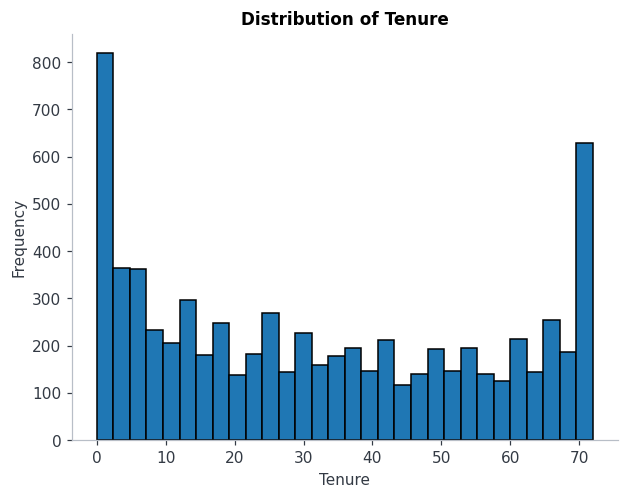

In [25]:
# histogram of tenure
import matplotlib.pyplot as plt

plt.hist(df['tenure'], bins=30, edgecolor='black')
plt.xlabel('Tenure')
plt.ylabel('Frequency')
plt.title('Distribution of Tenure')
plt.show()

,min,median,max,skew,n_outliers,pct_outliers
column,,,,,,
tenure,0.0,29.0,72.0,0.24,0,0.00
CustomerAge,18.0,44.0,90.0,0.49,0,0.00
AnnualIncome,18000.0,55841.0,250000.0,1.40,242,3.47
MonthlyCallMinutes,0.0,494.5,1161.5,-0.49,7,0.10
AveragePaymentDelayDays,0.0,2.5,24.0,1.85,317,4.55
CustomerSatisfactionScore,1.5,6.9,10.0,-0.16,23,0.33


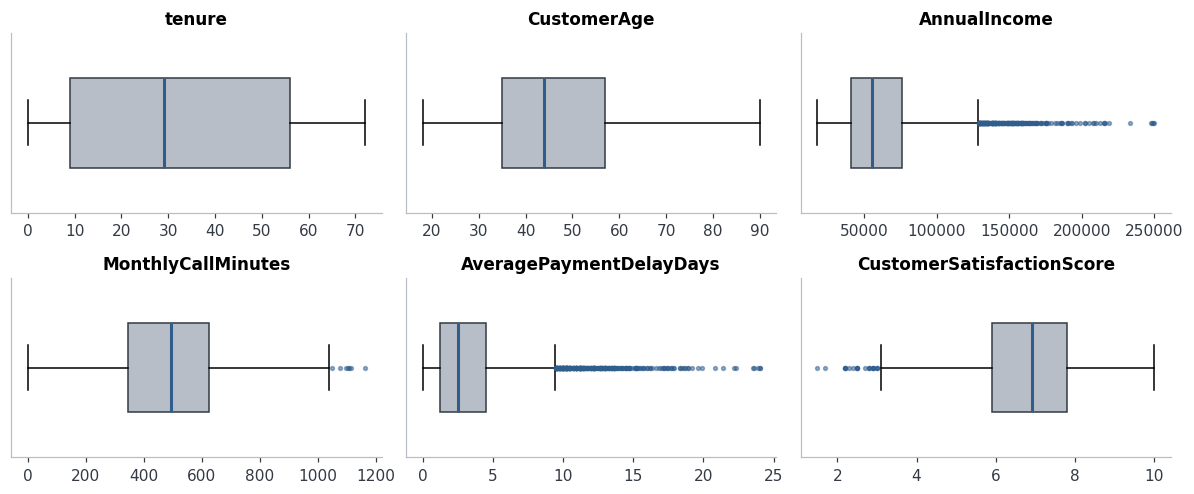

Customers with tenure = 0: 11
{('Two year', 'No'): 10, ('One year', 'No'): 1}


In [43]:

# Check for outliers using original non-missing values

rows = []

for c in num_cols:
    s = raw[c].dropna()

    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1

    out = (
        (s < q1 - 1.5 * iqr)
        | (s > q3 + 1.5 * iqr)
    )

    rows.append({
        "column": c,
        "min": s.min(),
        "median": s.median(),
        "max": s.max(),
        "skew": s.skew(),
        "n_outliers": int(out.sum()),
        "pct_outliers": 100 * out.mean()
    })

display(
    pd.DataFrame(rows)
    .set_index("column")
    .round(2)
)

fig, axes = plt.subplots(2, 3, figsize=(11, 4.6))

for ax, c in zip(axes.ravel(), num_cols):
    ax.boxplot(
        raw[c].dropna(),
        orientation='horizontal',
        widths=0.5,
        patch_artist=True,
        boxprops=dict(
            facecolor=NEUTRAL,
            color=INK
        ),
        medianprops=dict(
            color=ACCENT,
            lw=2
        ),
        flierprops=dict(
            marker="o",
            markersize=2.5,
            markerfacecolor=ACCENT,
            markeredgecolor=ACCENT,
            alpha=0.5
        )
    )

    ax.set_title(c)
    ax.set_yticks([])

plt.tight_layout()
plt.show()

print(
    "Customers with tenure = 0:",
    int((raw["tenure"] == 0).sum())
)

print(
    raw.loc[
        raw["tenure"] == 0,
        ["Contract", "Churn"]
    ].value_counts().to_dict()
)



### What We Found

Overall, the numeric values were within the expected ranges.

- There were no negative values.
- Customer ages ranged from 18 to 90.
- Satisfaction scores stayed within the expected range of 1 to 10.
- Tenure did not exceed 72 months.

The two columns with the most outliers were:

- `AnnualIncome`: About 3.5% of values were flagged.
- `AveragePaymentDelayDays`: About 4.5% of values were flagged.

We also found 11 customers with a tenure of zero months. All 11 had either one-year or two-year contracts, and none had churned.

This could make sense if those customers were still very new.

### Our Decision

We decided to keep the outliers because we didn't find anything that clearly indicated they were mistakes.

For example, a customer could realistically have an annual income of $250,000 or make a payment 24 days late.

Removing these observations could mean losing useful information about customers who behave differently from the average.

If these values become a problem when we start modeling, we can consider transformations at that point. For now, we decided to leave them as they are.


In [26]:
# change CustomerAge to integer type
df['CustomerAge'] = df['CustomerAge'].astype(int)
df['CustomerAge'].dtype  # Verify the change
df.head()

,customerID,gender,SeniorCitizen,tenure,InternetService,TechSupport,Contract,PaperlessBilling,PaymentMethod,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore,Churn,Churn_Binary
0,7590-VHVEG,Female,No,1.0,DSL,No,Month-to-month,No,Electronic check,77,39408.0,0.0,11.4,6.0,No,0
1,5575-GNVDE,Male,No,34.0,DSL,No,One year,Yes,Mailed check,22,102292.0,375.1,0.5,6.6,No,0
2,3668-QPYBK,Male,No,2.0,DSL,No,Month-to-month,Yes,Mailed check,43,26869.0,373.6,3.4,6.2,Yes,1
3,7795-CFOCW,Male,No,45.0,DSL,Yes,One year,Yes,Electronic check,71,90565.0,0.0,1.4,6.8,No,0
4,9237-HQITU,Female,No,2.0,Fiber optic,No,Month-to-month,Yes,Electronic check,46,83510.0,221.7,5.8,6.3,Yes,1


In [27]:
# Create AgeGroup column using pd.cut
import pandas as pd
age_bins = [0, 25, 40, 55, 70, float("inf")]
age_labels = ["Under 25", "25-39", "40-54", "55-69", "70+"]

df["AgeGroup"] = pd.cut(
    df["CustomerAge"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

df["AgeGroup"].head()

0         70+
1    Under 25
2       40-54
3         70+
4       40-54
Name: AgeGroup, dtype: category
Categories (5, object): ['Under 25' < '25-39' < '40-54' < '55-69' < '70+']


### Creating Age Groups

We created a new column called `AgeGroup` by dividing customers into five age ranges:

- Under 25
- 25–39
- 40–54
- 55–69
- 70+

We kept the original `CustomerAge` column because the exact age could still be useful when modeling.

The main reason we created age groups was to make it easier to compare churn rates across different age ranges.

This could help us identify patterns that might not be as obvious when looking at age as a continuous variable.


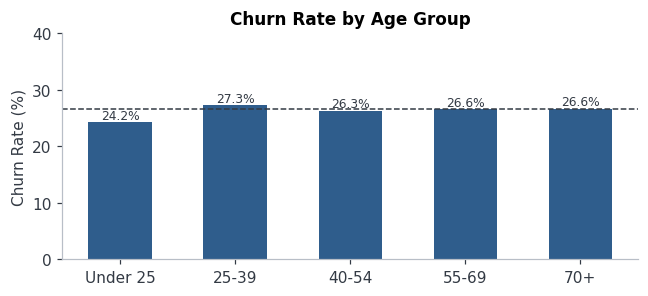

In [44]:

# Compare churn rates across age groups

age_rate = df.groupby(
    "AgeGroup",
    observed=True
)["Churn_Binary"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(6, 2.8))

ax.bar(
    age_rate.index.astype(str),
    age_rate["mean"] * 100,
    color=ACCENT,
    width=0.55
)

ax.axhline(
    df["Churn_Binary"].mean() * 100,
    color=INK,
    lw=1,
    ls="--"
)

for x, (m, n) in enumerate(
    zip(age_rate["mean"], age_rate["size"])
):
    ax.text(
        x,
        m * 100 + 0.6,
        f"{m:.1%}",
        ha="center",
        fontsize=8,
        color=INK
    )

ax.set_ylim(0, 40)
ax.set_ylabel("Churn Rate (%)")
ax.set_title("Churn Rate by Age Group")

plt.tight_layout()
plt.show()



### Churn Rates by Age Group

After creating the age groups, we compared their churn rates.

We noticed that churn rates were very similar across all five groups.

This suggests that age alone may not be particularly helpful for predicting which customers will leave.

However, we decided to keep both `CustomerAge` and `AgeGroup` because age could still be useful when combined with other variables.


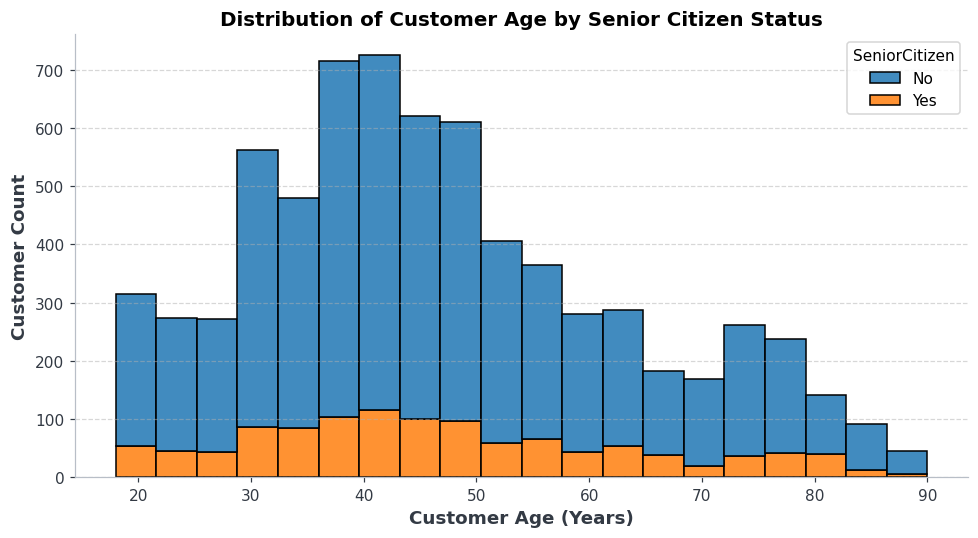

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="CustomerAge",
    hue="SeniorCitizen",
    multiple="stack",
    bins=20,  # Combines individual ages into 20 clean intervals
    palette=["#1f77b4", "#ff7f0e"],
    edgecolor="black",
    alpha=0.85,
)

plt.xlabel("Customer Age (Years)", fontsize=12, fontweight="bold")
plt.ylabel("Customer Count", fontsize=12, fontweight="bold")
plt.title(
    "Distribution of Customer Age by Senior Citizen Status",
    fontsize=13,
    fontweight="bold",
)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### Checking SeniorCitizen Against CustomerAge

When we compared `SeniorCitizen` with `CustomerAge`, we noticed something that didn't make sense.

Some customers in their 20s and 30s, also 18 year olds were marked as senior citizens, while many older customers weren't.

Since we would normally expect senior citizen status to be related to age, we wanted to investigate this further.

We looked at the distribution of ages for customers marked as seniors and compared it with customers who weren't.


Flagged senior but under 65: 937 of 1,130 seniors (83%)
Aged 65+ but NOT flagged senior: 936 of 1,129 customers aged 65+
Mean age -> senior: 47.1 | not senior: 46.6


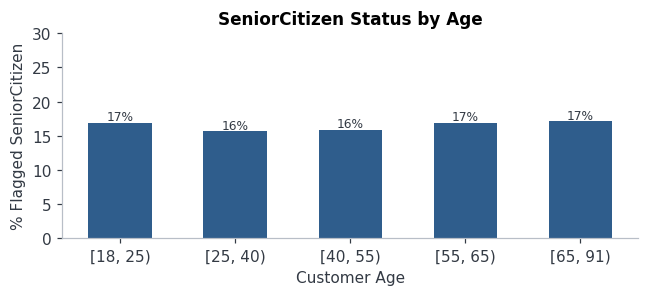

In [45]:

# Check whether SeniorCitizen matches CustomerAge
# Use original values and exclude missing ages

r = raw.dropna(subset=["CustomerAge"]).copy()
r["senior"] = r["SeniorCitizen"] == "Yes"

print(
    f"Flagged senior but under 65: "
    f"{(r.senior & (r.CustomerAge < 65)).sum():,} "
    f"of {r.senior.sum():,} seniors "
    f"({(r.senior & (r.CustomerAge < 65)).sum() / r.senior.sum():.0%})"
)

print(
    f"Aged 65+ but NOT flagged senior: "
    f"{(~r.senior & (r.CustomerAge >= 65)).sum():,} "
    f"of {(r.CustomerAge >= 65).sum():,} customers aged 65+"
)

print(
    "Mean age -> senior:",
    round(r.loc[r.senior, 'CustomerAge'].mean(), 1),
    "| not senior:",
    round(r.loc[~r.senior, 'CustomerAge'].mean(), 1)
)

share = (
    r.groupby(
        pd.cut(
            r["CustomerAge"],
            [18, 25, 40, 55, 65, 91],
            right=False
        ),
        observed=True
    )["senior"].mean() * 100
)

fig, ax = plt.subplots(figsize=(6, 2.8))

ax.bar(
    share.index.astype(str),
    share.values,
    color=ACCENT,
    width=0.55
)

for x, v in enumerate(share.values):
    ax.text(
        x,
        v + 0.4,
        f"{v:.0f}%",
        ha="center",
        fontsize=8,
        color=INK
    )

ax.set_ylim(0, 30)
ax.set_ylabel("% Flagged SeniorCitizen")
ax.set_xlabel("Customer Age")
ax.set_title("SeniorCitizen Status by Age")

plt.tight_layout()
plt.show()



### What We Found

After looking more closely, we found that `SeniorCitizen` doesn't appear to match `CustomerAge`.

A few things stood out:

- Customers marked as senior citizens and those who weren't both had an average age of about 47.
- Roughly 16% of customers were marked as seniors across almost every age range, even among customers under 25.
- Most customers who were 65 or older weren't marked as senior citizens.

This suggests that there may be an issue with one of these columns, although we can't say for certain which one is incorrect.

### Our Decision

We decided to remove `SeniorCitizen` and keep `CustomerAge`, along with our new `AgeGroup` column.

We felt more comfortable keeping age because the data dictionary clearly identifies it as the customer's age in years.

It also gives us more detailed information than a simple Yes/No category.

We checked the relationship with churn and found that neither variable seemed particularly strong.

- Customers marked as seniors had a churn rate of 25.2%.
- Customers not marked as seniors had a churn rate of 26.8%.
- Churn rates were also fairly similar across our age groups.

Because of this, we don't expect removing `SeniorCitizen` to have much impact on our model.

Ideally, we would want to confirm the correct information with the data owner, but for now, we think keeping age is the better choice.


In [29]:
# drop senior citizen column
df = df.drop(columns=['SeniorCitizen'])

# check the first few rows of the modified DataFrame
df.head()

,customerID,gender,tenure,InternetService,TechSupport,Contract,PaperlessBilling,PaymentMethod,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore,Churn,Churn_Binary,AgeGroup
0,7590-VHVEG,Female,1.0,DSL,No,Month-to-month,No,Electronic check,77,39408.0,0.0,11.4,6.0,No,0,70+
1,5575-GNVDE,Male,34.0,DSL,No,One year,Yes,Mailed check,22,102292.0,375.1,0.5,6.6,No,0,Under 25
2,3668-QPYBK,Male,2.0,DSL,No,Month-to-month,Yes,Mailed check,43,26869.0,373.6,3.4,6.2,Yes,1,40-54
3,7795-CFOCW,Male,45.0,DSL,Yes,One year,Yes,Electronic check,71,90565.0,0.0,1.4,6.8,No,0,70+
4,9237-HQITU,Female,2.0,Fiber optic,No,Month-to-month,Yes,Electronic check,46,83510.0,221.7,5.8,6.3,Yes,1,40-54


In [30]:
# round the customer satisfaction score to the nearest integer
df['CustomerSatisfactionScore'] = df['CustomerSatisfactionScore'].round().astype(int)
df.head()

,customerID,gender,tenure,InternetService,TechSupport,Contract,PaperlessBilling,PaymentMethod,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore,Churn,Churn_Binary,AgeGroup
0,7590-VHVEG,Female,1.0,DSL,No,Month-to-month,No,Electronic check,77,39408.0,0.0,11.4,6,No,0,70+
1,5575-GNVDE,Male,34.0,DSL,No,One year,Yes,Mailed check,22,102292.0,375.1,0.5,7,No,0,Under 25
2,3668-QPYBK,Male,2.0,DSL,No,Month-to-month,Yes,Mailed check,43,26869.0,373.6,3.4,6,Yes,1,40-54
3,7795-CFOCW,Male,45.0,DSL,Yes,One year,Yes,Electronic check,71,90565.0,0.0,1.4,7,No,0,70+
4,9237-HQITU,Female,2.0,Fiber optic,No,Month-to-month,Yes,Electronic check,46,83510.0,221.7,5.8,6,Yes,1,40-54



### Final Data Type Adjustments

We made a couple of final adjustments to the numeric variables.

**CustomerAge**

We converted `CustomerAge` to an integer because it represents a customer's age in whole years.

**CustomerSatisfactionScore**

We rounded `CustomerSatisfactionScore` to the nearest whole number and converted it to an integer.

These changes make the values easier to work with and interpret. However, rounding satisfaction scores does remove some detail from the original measurements, so this is something we may want to revisit when modeling.


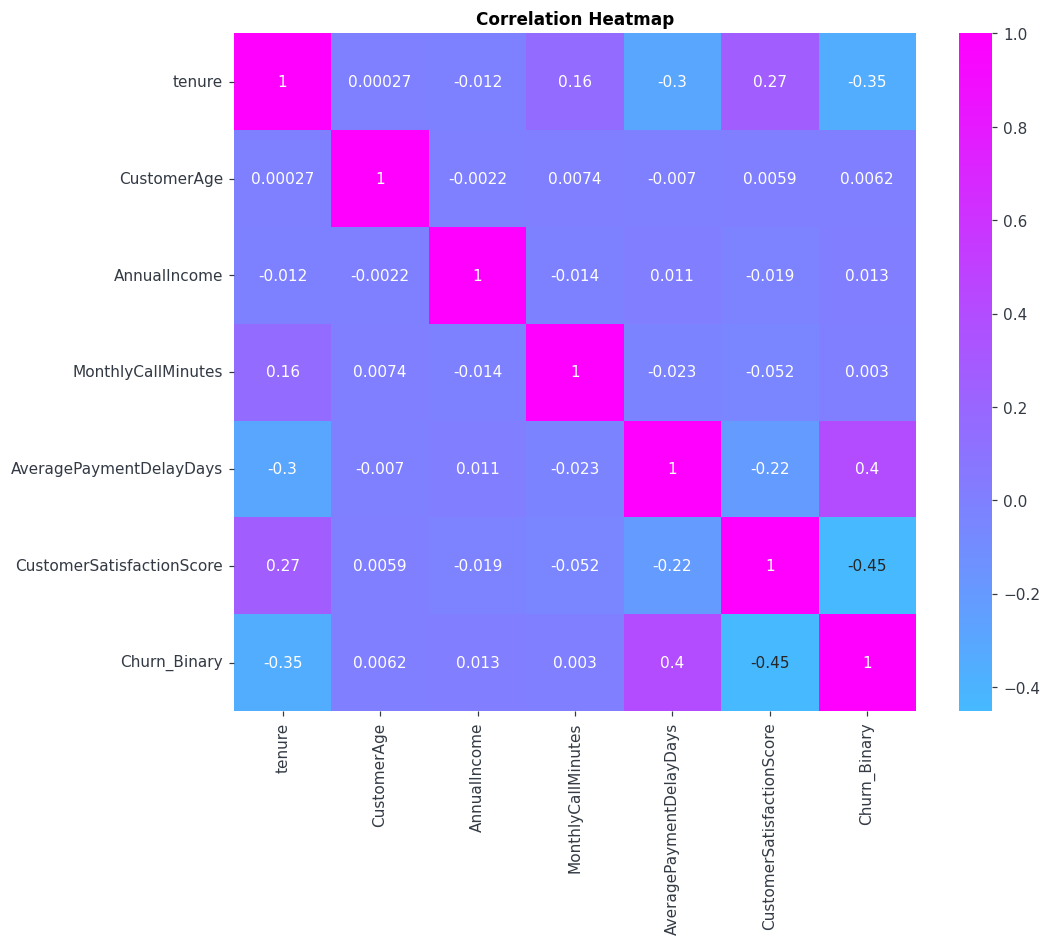

In [31]:
# correlation heatmap for numeric columns

import matplotlib.pyplot as plt
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='cool', center=0)
plt.title('Correlation Heatmap')
plt.show()


### What the Correlation Heatmap Tells Us

We used a correlation heatmap to get a better idea of which numeric variables are related to churn and whether any of our predictors are strongly related to one another.

**Variables Most Related to Churn**

Three variables stood out:

- `CustomerSatisfactionScore`: r = -0.45
- `AveragePaymentDelayDays`: r = 0.40
- `tenure`: r = -0.35

These relationships suggest that customers who are less satisfied, pay later, or haven't been with the company as long are more likely to churn.

On the other hand, `CustomerAge`, `AnnualIncome`, and `MonthlyCallMinutes` had almost no linear relationship with churn.

**Relationships Between Predictors**

We also checked whether any numeric predictors were strongly correlated with each other.

The strongest relationships were:

- Tenure and payment delay: r = -0.30
- Tenure and customer satisfaction: r = 0.27

Neither relationship is especially strong, so we don't see an obvious multicollinearity issue among the numeric variables based on this heatmap.

### Why This Matters

One thing we noticed is that the three numeric variables most related to churn also had missing values that we estimated earlier.

Because these variables may be important for predicting churn, we need to remember that some of their values are estimates.

Overall, the heatmap gives us a better idea of which variables may be worth paying attention to when we start modeling.


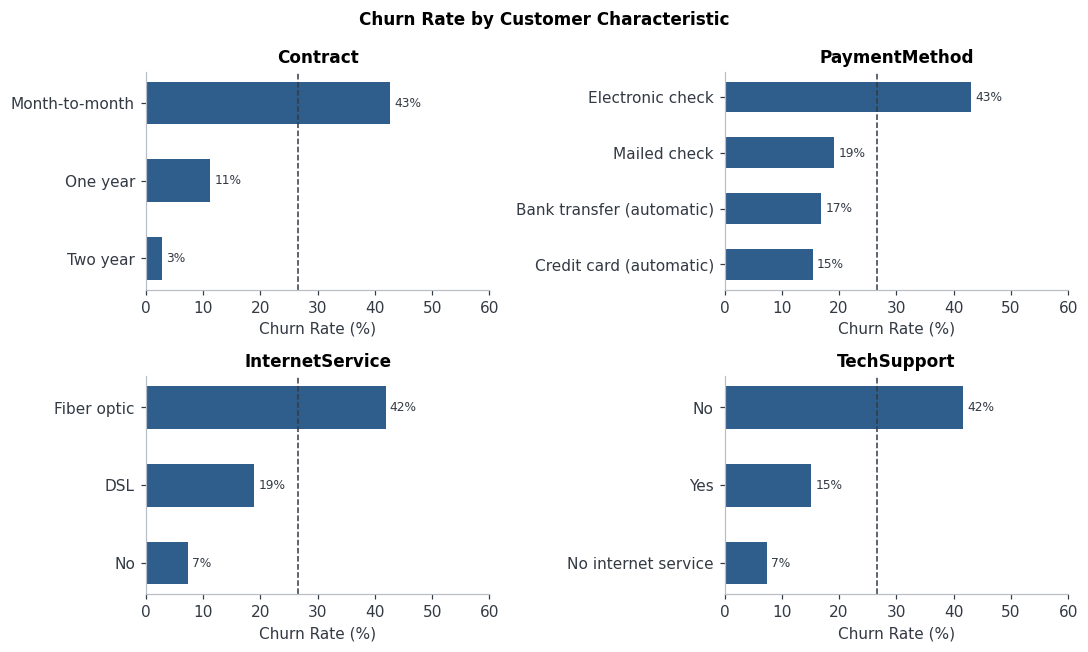

In [46]:

# Compare churn rates across categorical variables

cats = [
    "Contract",
    "PaymentMethod",
    "InternetService",
    "TechSupport"
]

overall = df["Churn_Binary"].mean() * 100

fig, axes = plt.subplots(2, 2, figsize=(10, 6))

for ax, c in zip(axes.ravel(), cats):

    r_ = (
        df.groupby(c)["Churn_Binary"]
        .mean()
        .mul(100)
        .sort_values()
    )

    ax.barh(
        r_.index,
        r_.values,
        color=ACCENT,
        height=0.55
    )

    ax.axvline(
        overall,
        color=INK,
        lw=1,
        ls="--"
    )

    for y, v in enumerate(r_.values):
        ax.text(
            v + 0.7,
            y,
            f"{v:.0f}%",
            va="center",
            fontsize=8,
            color=INK
        )

    ax.set_xlim(0, 60)
    ax.set_title(c)
    ax.set_xlabel("Churn Rate (%)")

plt.suptitle(
    "Churn Rate by Customer Characteristic",
    fontsize=11,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### Churn Rates by Customer Characteristics

Next, we looked at how churn rates differed across categorical variables, including contract type, payment method, internet service, and tech support.

We noticed some much larger differences than we saw with age or phone service.

**Contract Type**

Customers with month-to-month contracts had a churn rate of about 43%, compared with only about 3% for customers with two-year contracts.

This is one of the biggest differences we've noticed so far.

**Internet Service**

Customers with fiber-optic internet had a churn rate of about 42%, while customers without internet service had a churn rate of about 7%.

**Payment Method**

Customers paying by electronic check had a higher churn rate than customers using other payment methods.

This is especially important because we filled the missing `PaymentMethod` values with "Electronic check" earlier in the cleaning process.

### What This Means

These results suggest that some categorical variables may be more helpful for predicting churn than others.

We haven't built a model yet, so we can't say how important each variable will actually be. However, these patterns give us a better idea of what to look at moving forward.



## Final Validation and Cleaning Summary

Now that we've finished our main cleaning steps, we want to make sure the dataset is ready to use.

We ran a few final checks to confirm that:

- There are no remaining missing values.
- There are no duplicate rows or customer IDs.
- Numeric values are within reasonable ranges.
- Categorical columns contain the expected labels.
- `Churn_Binary` correctly matches the original `Churn` values.

We also compared the original and cleaned dataset shapes to make sure we understood which columns had been added or removed.

These checks help us catch any issues that may have been introduced during cleaning.


In [32]:
print("Original shape:", raw.shape)
print("Cleaned shape:", df.shape)

# Check missing values, including newly created columns
df.isna().sum()

Original shape: (7043, 17)
Cleaned shape: (7043, 16)


customerID                   0
gender                       0
tenure                       0
InternetService              0
TechSupport                  0
Contract                     0
PaperlessBilling             0
PaymentMethod                0
CustomerAge                  0
AnnualIncome                 0
MonthlyCallMinutes           0
AveragePaymentDelayDays      0
CustomerSatisfactionScore    0
Churn                        0
Churn_Binary                 0
AgeGroup                     0
dtype: int64

In [33]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print("Missing customer IDs:", df["customerID"].isna().sum())

Duplicate rows: 0
Duplicate customer IDs: 0
Missing customer IDs: 0


In [34]:
# Review numeric values after imputation and cleaning
df.describe()

,tenure,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore,Churn_Binary
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,32.421994,46.682380,62124.334854,466.949357,3.327239,6.862985,0.265370
std,24.135441,16.493811,29271.179792,225.508728,2.989463,1.417462,0.441561
min,0.000000,18.000000,18000.000000,0.000000,0.000000,2.000000,0.000000
25%,9.000000,35.000000,41512.500000,347.800000,1.200000,6.000000,0.000000
50%,29.981740,44.000000,56164.000000,493.200000,2.500000,7.000000,0.000000
75%,54.000000,56.500000,75909.000000,622.150000,4.500000,8.000000,1.000000
max,72.000000,90.000000,250000.000000,1161.500000,24.000000,10.000000,1.000000


In [35]:
invalid_values = pd.Series({
    "Negative tenure": (df["tenure"] < 0).sum(),
    "Negative age": (df["CustomerAge"] < 0).sum(),
    "Negative income": (df["AnnualIncome"] < 0).sum(),
    "Negative call minutes": (df["MonthlyCallMinutes"] < 0).sum(),
    "Negative payment delay": (df["AveragePaymentDelayDays"] < 0).sum(),
    "Satisfaction outside 1–10": (
        ~df["CustomerSatisfactionScore"].between(1, 10)
        & df["CustomerSatisfactionScore"].notna()
    ).sum()
})

invalid_values

Negative tenure              0
Negative age                 0
Negative income              0
Negative call minutes        0
Negative payment delay       0
Satisfaction outside 1–10    0
dtype: int64

In [36]:
# Show the labels and counts for each categorical column
for column in df.select_dtypes(include=["object", "string", "category"]).columns:
    if column != "customerID":
        print(f"\n{column}")
        print(df[column].value_counts(dropna=False))


gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

TechSupport
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

Contract
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

PaperlessBilling
PaperlessBilling
Yes    4171
No     2872
Name: count, dtype: int64

PaymentMethod
PaymentMethod
Electronic check             2542
Mailed check                 1548
Bank transfer (automatic)    1484
Credit card (automatic)      1469
Name: count, dtype: int64

Churn
Churn
No     5174
Yes    1869
Name: count, dtype: int64

AgeGroup
AgeGroup
40-54       2479
25-39       2098
55-69       1049
70+          897
Under 25     520
Name: count, dtype: int64


In [37]:
pd.crosstab(df["Churn"], df["Churn_Binary"], dropna=False)

Churn_Binary,0,1
Churn,,
No,5174,0
Yes,0,1869


In [38]:
df.to_csv("Churn_cleaned.csv", index=False)

# Data Summary, Data Visualization, and Simple Models

In [1]:
## Reload/Verify Clean Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure cleaned dataset is ready
df = pd.read_csv("Churn_cleaned.csv")
df.head()

,customerID,gender,tenure,InternetService,TechSupport,Contract,PaperlessBilling,PaymentMethod,CustomerAge,AnnualIncome,MonthlyCallMinutes,AveragePaymentDelayDays,CustomerSatisfactionScore,Churn,Churn_Binary,AgeGroup
0,7590-VHVEG,Female,1.0,DSL,No,Month-to-month,No,Electronic check,77,39408.0,0.0,11.4,6,No,0,70+
1,5575-GNVDE,Male,34.0,DSL,No,One year,Yes,Mailed check,22,102292.0,375.1,0.5,7,No,0,Under 25
2,3668-QPYBK,Male,2.0,DSL,No,Month-to-month,Yes,Mailed check,43,26869.0,373.6,3.4,6,Yes,1,40-54
3,7795-CFOCW,Male,45.0,DSL,Yes,One year,Yes,Electronic check,71,90565.0,0.0,1.4,7,No,0,70+
4,9237-HQITU,Female,2.0,Fiber optic,No,Month-to-month,Yes,Electronic check,46,83510.0,221.7,5.8,6,Yes,1,40-54


## Define Research Questions
1. How do tenure and customer satisfaction together relate to churn? Do they act as independent warning signals, or does one explain the other? (2 & 3 combined)
2. Does tech support reduce churn, and does it help more for some customers?
3. Which combinations of characteristics create the highest-risk segment?
4. Are the apparent effects of contract and payment method on churn real, or are they explained by other variables, such as tenure, satisfaction, payment delay and age? (combined with age)
5. How accurately can we predict churn, and which model is better?
6. If the company can only contact the riskiest 10–20% of customers, how many churners would it catch?


## Setup (Data Cleaning Fixes, Splitting, Encoding & Scaling)

In [ ]:



# 1. Fix Cleaning Issues

# Create Churn_Binary if it does not exist
if 'Churn_Binary' not in df.columns:
    df['Churn_Binary'] = df['Churn'].map({'Yes': 1, 'No': 0, 1: 1, 0: 0})

# Fill missing PaymentMethod values with the most common value
df['PaymentMethod'] = df['PaymentMethod'].fillna(
    df['PaymentMethod'].mode()[0]
)

# Round tenure to whole numbers
df['tenure'] = df['tenure'].round().astype(int)


# 2. Select Predictors and Target

predictor_cols = [
    'tenure',
    'CustomerSatisfactionScore',
    'AveragePaymentDelayDays',
    'CustomerAge',
    'MonthlyCallMinutes',
    'AnnualIncome',
    'Contract',
    'PaymentMethod',
    'InternetService',
    'TechSupport',
    'PaperlessBilling'
]

X = df[predictor_cols]
y = df['Churn_Binary']


# 3. Convert Categories into Numbers

X = pd.get_dummies(X, drop_first=True)


# 4. Split into Training and Testing Data

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=616
)


# 5. Standardize Numeric Predictors

num_cols = [
    'tenure',
    'CustomerSatisfactionScore',
    'AveragePaymentDelayDays',
    'CustomerAge',
    'MonthlyCallMinutes',
    'AnnualIncome'
]

scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])


# 6. Show Dataset Sizes

print("Dataset successfully prepared!")
print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

Dataset successfully prepared!
Training observations: 5634
Testing observations: 1409


#### Library Imports 

In [38]:
# Import libraries
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from scipy import stats
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,

f1_score, roc_auc_score, roc_curve,

confusion_matrix)
SEED = 616

# Set up plots
sns.set_theme(style="whitegrid")

## Define Research Questions
1. How do tenure and customer satisfaction together relate to churn? Do they act as independent warning signals, or does one explain the other? (2 & 3 combined)
2. Does tech support reduce churn, and does it help more for some customers?
3. Which combinations of characteristics create the highest-risk segment?
4. Are the apparent effects of contract and payment method on churn real, or are they explained by other variables, such as tenure, satisfaction, payment delay and age? (combined with age)
5. How accurately can we predict churn, and which model is better?
6. If the company can only contact the riskiest 10–20% of customers, how many churners would it catch?


### Research Questions and Key Findings

**Question 1**: How do tenure and customer satisfaction together relate to churn? Do they act as independent warning signals, or does one explain the other? 


Method: Bin tenure ($0\text{--}12, 13\text{--}36, 37+$ months) and satisfaction ($\le 5, 5\text{--}6.5, 6.5\text{--}8, >8$) into a pivot table heatmap. 

=== Churn Rate by Satisfaction and Tenure Band ===


TenureBand,0–12 Mo,13–36 Mo,37+ Mo
SatBand,,,
≤ 5.0,79.3%,62.8%,43.8%
5.1–6.5,55.1%,34.5%,18.1%
6.6–8.0,27.6%,15.1%,6.5%
> 8.0,9.9%,4.0%,2.8%



=== Customer Counts per Cell ===


TenureBand,0–12 Mo,13–36 Mo,37+ Mo
SatBand,,,
≤ 5.0,517,328,283
5.1–6.5,612,522,531
6.6–8.0,850,912,1702
> 8.0,121,199,466


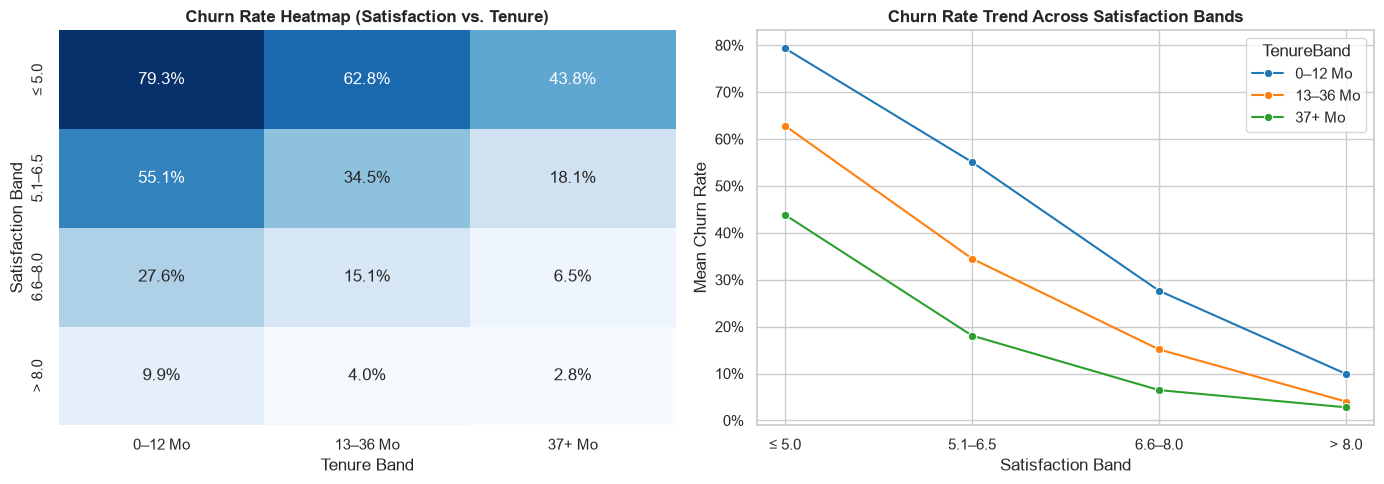

=== Odds Ratios Comparison (Standardized) ===


,Model 1 (Tenure Only),Model 2 (Sat Only),Model 3 (Both Integrated)
Tenure (per 1 SD),0.382,NaN,0.443
Satisfaction (per 1 SD),NaN,0.278,0.309


In [22]:
# 1. Create Binned Bands
df['TenureBand'] = pd.cut(df['tenure'], bins=[-1, 12, 36, 120], labels=['0–12 Mo', '13–36 Mo', '37+ Mo'])
df['SatBand'] = pd.cut(df['CustomerSatisfactionScore'], bins=[0, 5.0, 6.5, 8.0, 10.0], labels=['≤ 5.0', '5.1–6.5', '6.6–8.0', '> 8.0'])

# 2. Build Pivot Tables
churn_pivot = df.pivot_table(index='SatBand', columns='TenureBand', values='Churn_Binary', aggfunc='mean')
count_pivot = df.pivot_table(index='SatBand', columns='TenureBand', values='Churn_Binary', aggfunc='size')

print("=== Churn Rate by Satisfaction and Tenure Band ===")
display(churn_pivot.map(lambda x: f"{x:.1%}"))
print("\n=== Customer Counts per Cell ===")
display(count_pivot)

# 3 & 4. Visualizations: Heatmap & Line Chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap
sns.heatmap(churn_pivot, annot=True, fmt=".1%", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title('Churn Rate Heatmap (Satisfaction vs. Tenure)', fontweight='bold')
axes[0].set_ylabel('Satisfaction Band')
axes[0].set_xlabel('Tenure Band')

# Line Chart
sns.lineplot(
    data=df.groupby(['SatBand', 'TenureBand'], observed=True)['Churn_Binary'].mean().reset_index(),
    x='SatBand', y='Churn_Binary', hue='TenureBand', palette='tab10', marker='o', ax=axes[1]
)
axes[1].set_title('Churn Rate Trend Across Satisfaction Bands', fontweight='bold')
axes[1].set_xlabel('Satisfaction Band')
axes[1].set_ylabel('Mean Churn Rate')
axes[1].yaxis.set_major_formatter('{x:.0%}')

plt.tight_layout()
plt.show()

# 5. Logistic Regressions (Standardized Variables on Train Set)
X_t = sm.add_constant(X_train[['tenure']])
X_s = sm.add_constant(X_train[['CustomerSatisfactionScore']])
X_ts = sm.add_constant(X_train[['tenure', 'CustomerSatisfactionScore']])

m_tenure = sm.Logit(y_train, X_t).fit(disp=False)
m_sat = sm.Logit(y_train, X_s).fit(disp=False)
m_both = sm.Logit(y_train, X_ts).fit(disp=False)

or_summary = pd.DataFrame({
    'Model 1 (Tenure Only)': [np.exp(m_tenure.params['tenure']), np.nan],
    'Model 2 (Sat Only)': [np.nan, np.exp(m_sat.params['CustomerSatisfactionScore'])],
    'Model 3 (Both Integrated)': [np.exp(m_both.params['tenure']), np.exp(m_both.params['CustomerSatisfactionScore'])]
}, index=['Tenure (per 1 SD)', 'Satisfaction (per 1 SD)']).round(3)

print("=== Odds Ratios Comparison (Standardized) ===")
display(or_summary)

#### Key Takeaways: 
- both tenure and customer satisfaction are strong independent drivers of churn
- model 3: the odds ratio is unchanged. neither variable explains the other, they are separate additive risk factors
- increase in satisfaction reduced odds of churn by around 69% while a 1-sd increase in tenure reduces churn odds by around 56%

- customers in their first year with satisfaction scores less than 5 expereince 79.3 percent churn rate
- churn drops once satisfaction reaches above 6.5. 


**Question 2**: Does tech support reduce churn, and does it help more for some customers?


=== Tech Support Impact by Internet Service & Contract ===


,InternetService,TechSupport,Contract,Churn_Rate,Avg_Satisfaction,Customer_Count
0,DSL,No,Month-to-month,35.9%,6.57,884
1,DSL,No,One year,9.8%,7.19,244
2,DSL,No,Two year,3.5%,7.51,115
3,DSL,Yes,Month-to-month,22.7%,7.03,339
4,DSL,Yes,One year,8.9%,7.60,326
5,DSL,Yes,Two year,1.6%,7.84,513
6,Fiber optic,No,Month-to-month,57.5%,5.98,1796
7,Fiber optic,No,One year,18.5%,6.76,313
8,Fiber optic,No,Two year,8.3%,7.16,121
9,Fiber optic,Yes,Month-to-month,38.9%,6.76,332


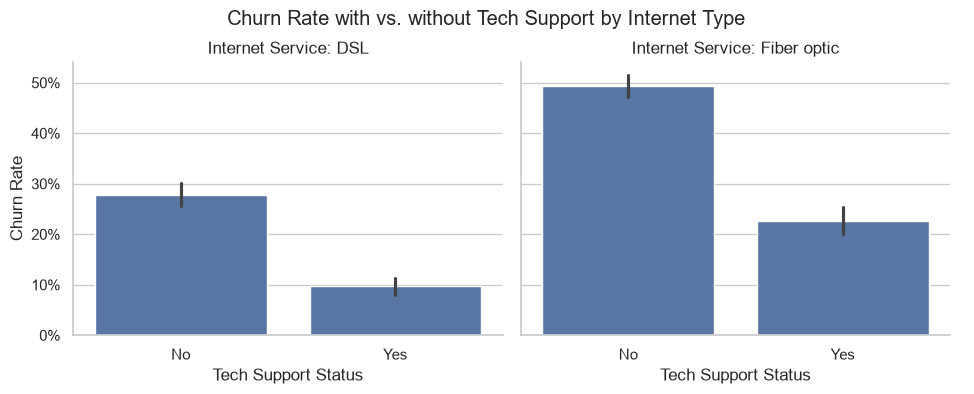

Tech Support Odds Ratio (Without Sat Score): 0.905
Tech Support Odds Ratio (With Sat Score Added): 1.170


In [26]:
# 1. Filter to customers with Internet Service
df_internet = df[df['InternetService'] != 'No'].copy()


# 2. Table: Churn Rate & Avg Satisfaction by Tech Support, Internet Type, and Contract
q2_table = df_internet.groupby(
    ['InternetService', 'TechSupport', 'Contract']
).agg(
    Churn_Rate=('Churn_Binary', 'mean'),
    Avg_Satisfaction=('CustomerSatisfactionScore', 'mean'),
    Customer_Count=('Churn_Binary', 'count')
).reset_index()

print("=== Tech Support Impact by Internet Service & Contract ===")
display(q2_table.style.format({
    'Churn_Rate': '{:.1%}',
    'Avg_Satisfaction': '{:.2f}'
}))


# 3. Grouped Bar Chart by Panel
g = sns.catplot(
    data=df_internet,
    x='TechSupport',
    y='Churn_Binary',
    col='InternetService',
    kind='bar',
    height=4,
    aspect=1.2
)

g.set_axis_labels("Tech Support Status", "Churn Rate")
g.set_titles("Internet Service: {col_name}")

for ax in g.axes.flat:
    ax.yaxis.set_major_formatter('{x:.0%}')

plt.subplots_adjust(top=0.85)
g.fig.suptitle("Churn Rate with vs. without Tech Support by Internet Type")
plt.show()


# 4 & 5. Logistic Regression with Interaction and Satisfaction Mediation

# Model 4A: Main effects + Interaction (TechSupport x Fiber Optic)
X_q2_a = X_train[
    ['TechSupport_Yes', 'InternetService_Fiber optic', 'tenure']
].copy()

X_q2_a['Tech_x_Fiber'] = (
    X_q2_a['TechSupport_Yes'] *
    X_q2_a['InternetService_Fiber optic']
)

X_q2_a = sm.add_constant(X_q2_a).astype(float)

m_q2_a = sm.Logit(
    y_train.astype(float), X_q2_a
).fit(disp=False)


# Model 4B: Add CustomerSatisfactionScore
X_q2_b = X_q2_a.copy()

X_q2_b['CustomerSatisfactionScore'] = (
    X_train['CustomerSatisfactionScore']
)

X_q2_b = X_q2_b.astype(float)

m_q2_b = sm.Logit(
    y_train.astype(float), X_q2_b
).fit(disp=False)


# Compare Tech Support Odds Ratios
print(
    f"Tech Support Odds Ratio (Without Sat Score): "
    f"{np.exp(m_q2_a.params['TechSupport_Yes']):.3f}"
)

print(
    f"Tech Support Odds Ratio (With Sat Score Added): "
    f"{np.exp(m_q2_b.params['TechSupport_Yes']):.3f}"
)

#### Key Takeaways: 
- having tech support is associated w significantly lower churn across both dsl and fiber optic
- fiber optic users without tech support have highest churn rates 


**Question 3**: Which combinations of characteristics create the highest-risk segment?


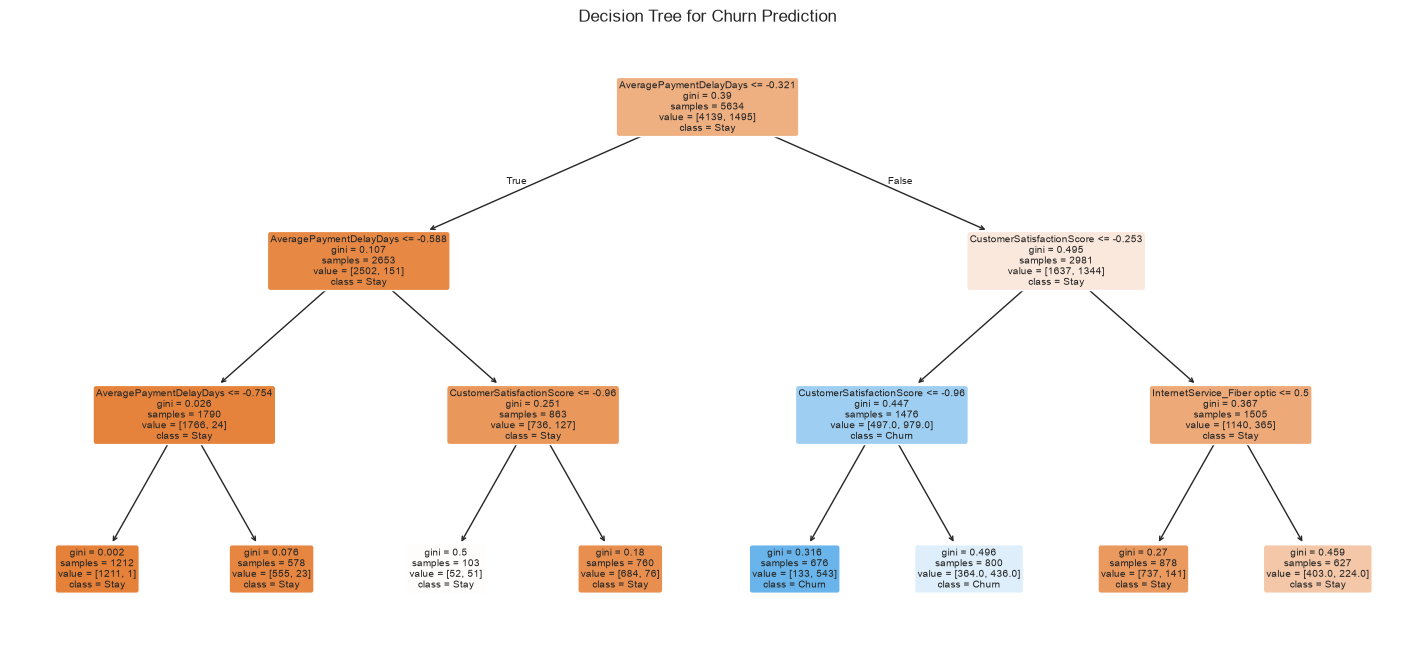

,Leaf,Customer_Count,Churn_Rate,Total_Churners,Share_of_All_Churners,High_Risk_Flag
4,10,676,80.3%,543,36.3%,True
5,11,800,54.5%,436,29.2%,True
2,6,103,49.5%,51,3.4%,False
7,14,627,35.7%,224,15.0%,False
6,13,878,16.1%,141,9.4%,False
3,7,760,10.0%,76,5.1%,False
1,4,578,4.0%,23,1.5%,False
0,3,1212,0.1%,1,0.1%,False


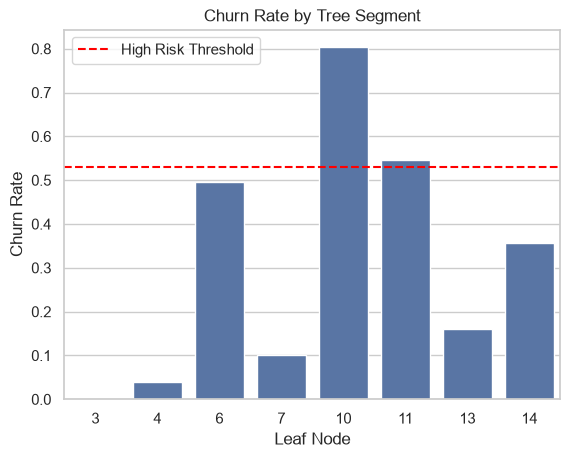

In [35]:
# 1. Train Decision Tree
dt_q3 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=616)
dt_q3.fit(X_train, y_train)


# 2. Visualize Decision Tree
plt.figure(figsize=(18, 8))

plot_tree(
    dt_q3,
    feature_names=X_train.columns,
    class_names=['Stay', 'Churn'],
    filled=True,
    rounded=True
)

plt.title("Decision Tree for Churn Prediction")
plt.show()


# 3. Create Segment Table
train_segments = pd.DataFrame({
    'Leaf': dt_q3.apply(X_train),
    'Churn': y_train
})

segment_summary = train_segments.groupby('Leaf').agg(
    Customer_Count=('Churn', 'count'),
    Churn_Rate=('Churn', 'mean'),
    Total_Churners=('Churn', 'sum')
).reset_index()

overall_churn_rate = y_train.mean()

segment_summary['Share_of_All_Churners'] = (
    segment_summary['Total_Churners'] / y_train.sum()
)

segment_summary['High_Risk_Flag'] = (
    (segment_summary['Churn_Rate'] >= 2 * overall_churn_rate) &
    (segment_summary['Customer_Count'] >= 100)
)

segment_summary = segment_summary.sort_values(
    'Churn_Rate', ascending=False
)

display(segment_summary.style.format({
    'Churn_Rate': '{:.1%}',
    'Share_of_All_Churners': '{:.1%}'
}))


# 4. Plot Churn Rate by Segment
sns.barplot(data=segment_summary, x='Leaf', y='Churn_Rate')

plt.axhline(
    2 * overall_churn_rate,
    color='red',
    linestyle='--',
    label='High Risk Threshold'
)

plt.title("Churn Rate by Tree Segment")
plt.xlabel("Leaf Node")
plt.ylabel("Churn Rate")
plt.legend()
plt.show()

#### Key Takeaways
- leaf 10 (highest risk): customers have 80.3% churn rate that have significant payment delays and low satisfaction
- leaf 11 (high risk): customers with payment delays and moderatly low satisfaction score churn at 54.5%
these two leaves represent 65.5% of all churners 


**Question 4**: Are the apparent effects of contract and payment method on churn real, or are they explained by other variables, such as tenure, satisfaction, payment delay and age? 


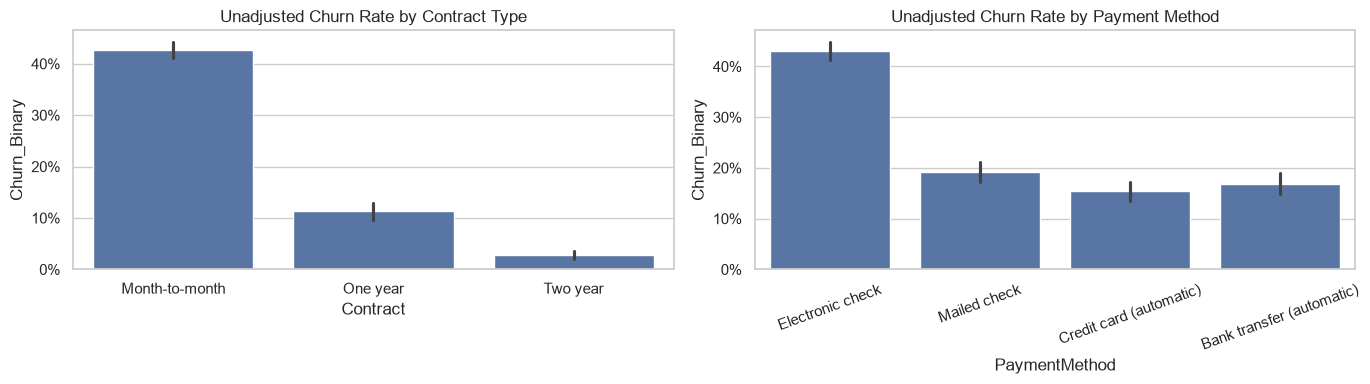

=== Confounding Factors Across Payment Methods ===


,PaymentMethod,Median_Tenure,Median_Sat,Median_Delay,Churn_Rate
0,Bank transfer (automatic),46.0,7.0,1.7,16.9
1,Credit card (automatic),45.0,7.0,1.6,15.4
2,Electronic check,21.0,6.0,4.2,43.1
3,Mailed check,16.0,7.0,2.4,19.2


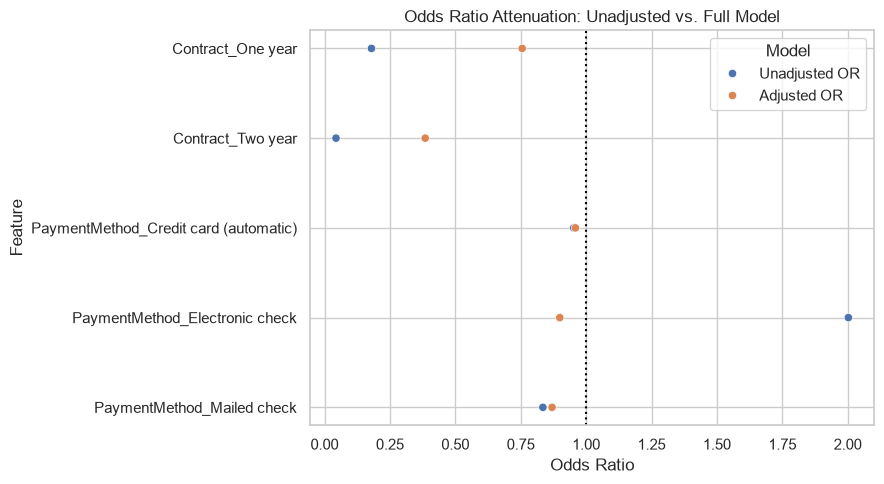

Chi-Square test for Age Group vs Paperless Billing: Chi2 = 0.17, p-value = 0.9821


In [36]:
# 1. Unadjusted Simple Churn Rates

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(data=df, x='Contract', y='Churn_Binary', ax=axes[0])
axes[0].set_title('Unadjusted Churn Rate by Contract Type')
axes[0].yaxis.set_major_formatter('{x:.0%}')

sns.barplot(data=df, x='PaymentMethod', y='Churn_Binary', ax=axes[1])
axes[1].set_title('Unadjusted Churn Rate by Payment Method')
axes[1].tick_params(axis='x', rotation=20)
axes[1].yaxis.set_major_formatter('{x:.0%}')

plt.tight_layout()
plt.show()


# 2. Confounding Table

confounding = df.groupby('PaymentMethod').agg(
    Median_Tenure=('tenure', 'median'),
    Median_Sat=('CustomerSatisfactionScore', 'median'),
    Median_Delay=('AveragePaymentDelayDays', 'median'),
    Churn_Rate=('Churn_Binary', 'mean')
).reset_index()

confounding['Churn_Rate'] = (confounding['Churn_Rate'] * 100).round(1)

print("=== Confounding Factors Across Payment Methods ===")
display(confounding)


# 3 & 4. Unadjusted vs Adjusted Full Model Logistic Regression

# Select Contract and Payment Method predictors
contract_pm_cols = [
    c for c in X_train.columns
    if c.startswith('Contract_') or c.startswith('PaymentMethod_')
]

# Simple model
X_simple = sm.add_constant(X_train[contract_pm_cols]).astype(float)
m_simple = sm.Logit(y_train.astype(float), X_simple).fit(disp=False)

# Full model
X_full = sm.add_constant(X_train).astype(float)
m_full = sm.Logit(y_train.astype(float), X_full).fit(disp=False)


# 5. Dot Plot Comparing Simple vs Adjusted Odds Ratios

or_simple = np.exp(m_simple.params[contract_pm_cols])
or_full = np.exp(m_full.params[contract_pm_cols])

comp_df = pd.DataFrame({
    'Feature': contract_pm_cols,
    'Unadjusted OR': or_simple.values,
    'Adjusted OR': or_full[contract_pm_cols].values
})

comp_df = comp_df.melt(
    id_vars='Feature',
    var_name='Model',
    value_name='Odds Ratio'
)

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=comp_df,
    x='Odds Ratio',
    y='Feature',
    hue='Model'
)

plt.axvline(1, color='black', linestyle=':')
plt.title('Odds Ratio Attenuation: Unadjusted vs. Full Model')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


# 6. Age Sub-question & Chi-Square Test

df['Age_Group'] = pd.qcut(df['CustomerAge'], q=4, duplicates='drop')

contingency_tab = pd.crosstab(
    df['Age_Group'],
    df['PaperlessBilling']
)

chi2, p_val, dof, expected = stats.chi2_contingency(contingency_tab)

print(
    f"Chi-Square test for Age Group vs Paperless Billing: "
    f"Chi2 = {chi2:.2f}, p-value = {p_val:.4f}"
)

#### Key Takeaways
- customers month to month contracts have unadjusted churn rate over 40% compared to 11%. 
long term contracts reduce churn potential 
- Electronic check users also churn at over 40%, but this is largely driven by shorter tenure and month-to-month contracts rather than the payment method itself.
- while older customers favor traditional billing methods (like mailed checks), age itself does not directly drive churn once contract length and tenure are controlled for
- 


**Question 5**: How accurately can we predict churn, and which model is better?


Best Tree Depth: {'max_depth': 5}


,Metric,Baseline,Logistic Regression,Decision Tree
0,Accuracy,0.7346,0.8290,0.8304
1,Precision,0.0000,0.7125,0.7170
2,Recall,0.0000,0.5963,0.5963
3,F1-Score,0.0000,0.6492,0.6511
4,ROC-AUC,0.5000,0.8773,0.8795


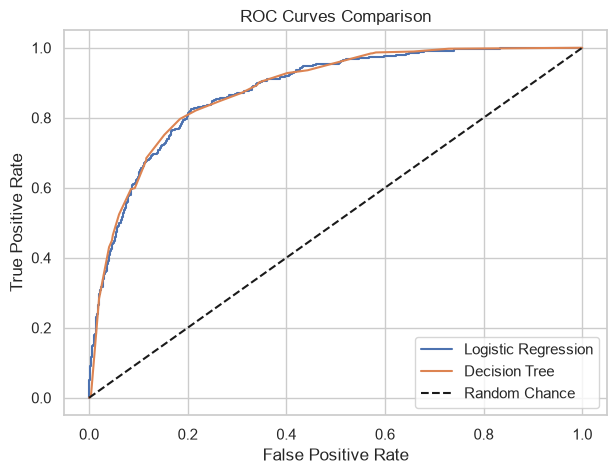

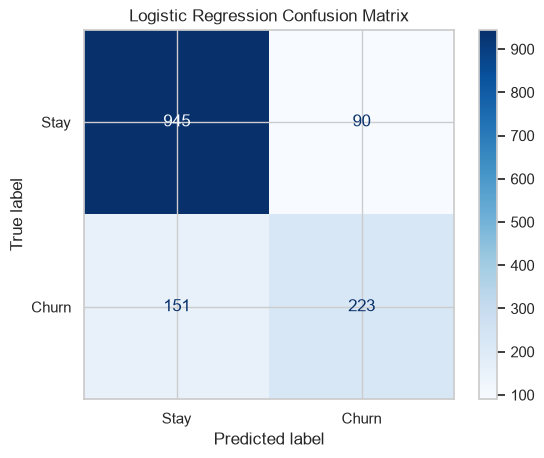

In [39]:
# 1. Baseline Accuracy
baseline_acc = (y_test == 0).mean()


# 2. Tune Decision Tree
param_grid = {'max_depth': [2, 3, 4, 5, 6, 8, 10]}

grid_tree = GridSearchCV(
    DecisionTreeClassifier(random_state=616),
    param_grid,
    cv=5,
    scoring='roc_auc'
)

grid_tree.fit(X_train, y_train)
best_dt = grid_tree.best_estimator_

print("Best Tree Depth:", grid_tree.best_params_)


# 3. Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=616)
lr_model.fit(X_train, y_train)


# 4. Make Predictions
y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

y_pred_dt = best_dt.predict(X_test)
y_prob_dt = best_dt.predict_proba(X_test)[:, 1]


# 5. Compare Model Performance
metrics_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Baseline': [baseline_acc, 0, 0, 0, 0.5],
    'Logistic Regression': [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_lr, zero_division=0),
        roc_auc_score(y_test, y_prob_lr)
    ],
    'Decision Tree': [
        accuracy_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_dt, zero_division=0),
        recall_score(y_test, y_pred_dt, zero_division=0),
        f1_score(y_test, y_pred_dt, zero_division=0),
        roc_auc_score(y_test, y_prob_dt)
    ]
})

display(metrics_summary.round(4))


# 6. Plot ROC Curves and Confusion Matrix
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, label='Logistic Regression')
plt.plot(fpr_dt, tpr_dt, label='Decision Tree')
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison')
plt.legend()
plt.show()


# Logistic Regression Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

ConfusionMatrixDisplay(
    cm_lr,
    display_labels=['Stay', 'Churn']
).plot(cmap='Blues')

plt.title('Logistic Regression Confusion Matrix')
plt.show()

#### Key Takeaways
- The Logistic Regression model achieves 82.9% overall accuracy on test data
- When predicting churn, the model achieves 71.2% precision
- The model correctly identifies 59.6% of actual churners

**Question 6**: If the company can only contact the riskiest 10–20% of customers, how many churners would it catch?


,Top Customers,Customers Contacted,Churners Captured,Share of Churners,Churn Rate,Lift
0,10%,140,115,30.7%,82.1%,3.09x
1,20%,281,204,54.5%,72.6%,2.74x
2,30%,422,269,71.9%,63.7%,2.40x


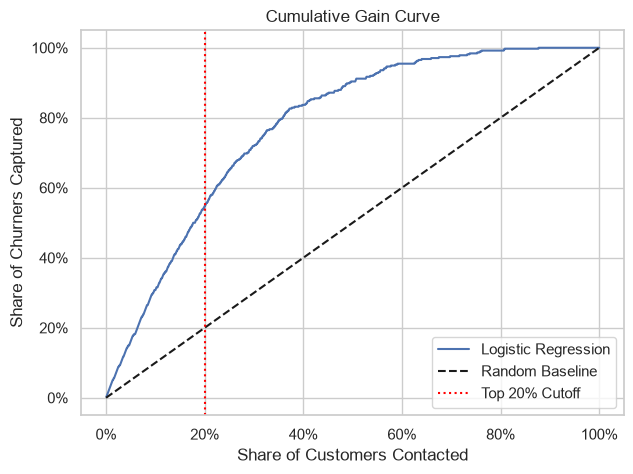

In [40]:
# 1. Rank Customers by Churn Risk
test_results = pd.DataFrame({
    'Churn': y_test,
    'Probability': y_prob_lr
}).sort_values('Probability', ascending=False).reset_index(drop=True)


# 2. Calculate Targeting Performance
total_churners = test_results['Churn'].sum()
overall_rate = test_results['Churn'].mean()

decile_metrics = []

for pct in [0.10, 0.20, 0.30]:
    k = int(len(test_results) * pct)
    top_customers = test_results.iloc[:k]

    churners = top_customers['Churn'].sum()
    churn_rate = top_customers['Churn'].mean()

    decile_metrics.append({
        'Top Customers': f'{int(pct * 100)}%',
        'Customers Contacted': k,
        'Churners Captured': churners,
        'Share of Churners': f'{churners / total_churners:.1%}',
        'Churn Rate': f'{churn_rate:.1%}',
        'Lift': f'{churn_rate / overall_rate:.2f}x'
    })

display(pd.DataFrame(decile_metrics))


# 3. Calculate Cumulative Gains
test_results['Cumulative Churners'] = test_results['Churn'].cumsum()
test_results['Gain'] = test_results['Cumulative Churners'] / total_churners
test_results['Customers Contacted'] = (
    (test_results.index + 1) / len(test_results)
)


# 4. Plot Cumulative Gain Curve
plt.figure(figsize=(7, 5))

plt.plot(
    test_results['Customers Contacted'],
    test_results['Gain'],
    label='Logistic Regression'
)

plt.plot([0, 1], [0, 1], 'k--', label='Random Baseline')
plt.axvline(0.20, color='red', linestyle=':', label='Top 20% Cutoff')

plt.title('Cumulative Gain Curve')
plt.xlabel('Share of Customers Contacted')
plt.ylabel('Share of Churners Captured')

plt.gca().xaxis.set_major_formatter('{x:.0%}')
plt.gca().yaxis.set_major_formatter('{x:.0%}')

plt.legend()
plt.show()

#### Key Takeaways
- Contacting just the top 20% riskiest customers captures approximately 55% of all churners in the customer base.
- contacting the top 10% captures ~35% of churners, while expanding to 40% captures over 80% of total churners
